In [1]:
import pandas as pd
import numpy as np

# Updated file name for the 10k dataset
df = pd.read_csv("SMB_Cyber_Risk_Dataset_10000_Rows.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nRisk Level Distribution:")
print(df["risk_level"].value_counts())

df.head()

Dataset Shape: (10000, 39)

Columns:
['company_size', 'industry', 'annual_revenue', 'employee_count', 'mfa_enabled', 'password_policy', 'privileged_accounts', 'firewall_enabled', 'network_segmentation', 'vpn_enabled', 'remote_access', 'antivirus_enabled', 'edr_enabled', 'device_encryption', 'patch_management', 'vulnerability_scanning', 'critical_vulnerabilities', 'asset_inventory', 'backup_enabled', 'backup_frequency', 'backup_tested', 'security_policy', 'incident_response_plan', 'business_continuity_plan', 'security_training', 'phishing_training', 'employee_access_control', 'data_encryption', 'data_classification', 'cloud_security', 'logging_enabled', 'siem_enabled', 'security_monitoring', 'vendor_risk_assessment', 'third_party_access', 'previous_incidents', 'incident_count_last_year', 'cyber_risk_score', 'risk_level']

Missing Values:
company_size                   0
industry                       0
annual_revenue                 0
employee_count                 0
mfa_enabled        

,company_size,industry,annual_revenue,employee_count,mfa_enabled,password_policy,privileged_accounts,firewall_enabled,network_segmentation,vpn_enabled,...,cloud_security,logging_enabled,siem_enabled,security_monitoring,vendor_risk_assessment,third_party_access,previous_incidents,incident_count_last_year,cyber_risk_score,risk_level
0,Micro,Logistics,0.30,12,Yes,Strong,3,Yes,No,Yes,...,Moderate,Yes,No,No,Yes,No,No,0,63,High
1,Micro,IT Services,1.64,11,Yes,Moderate,1,No,No,Yes,...,Weak,Yes,No,No,No,Yes,Yes,4,98,Critical
2,Small,Finance,9.51,60,Yes,Weak,7,Yes,Yes,Yes,...,Strong,Yes,No,Yes,Yes,No,No,0,61,High
3,Small,IT Services,11.66,98,No,Weak,9,Yes,Yes,Yes,...,Moderate,Yes,Yes,Yes,Yes,No,No,0,72,High
4,Small,Retail,2.25,23,Yes,Moderate,2,Yes,No,Yes,...,Strong,Yes,Yes,No,No,No,No,0,100,Critical


In [2]:
X = df.drop(columns=["risk_level", "cyber_risk_score"])
y = df["risk_level"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())

X shape: (10000, 37)
y shape: (10000,)

Target classes:
risk_level
Critical    6340
High        2753
Medium       863
Low           44
Name: count, dtype: int64


In [3]:
X["backup_frequency"] = X["backup_frequency"].fillna("Unknown")

print("Remaining missing values:", X.isnull().sum().sum())

Remaining missing values: 0


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

categorical_cols = X.select_dtypes(include=["object"]).columns
numeric_cols = X.select_dtypes(exclude=["object"]).columns

print("Categorical columns:", list(categorical_cols))
print("Numeric columns:", list(numeric_cols))

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", "passthrough", numeric_cols)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Categorical columns: ['company_size', 'industry', 'mfa_enabled', 'password_policy', 'firewall_enabled', 'network_segmentation', 'vpn_enabled', 'remote_access', 'antivirus_enabled', 'edr_enabled', 'device_encryption', 'patch_management', 'vulnerability_scanning', 'asset_inventory', 'backup_enabled', 'backup_frequency', 'backup_tested', 'security_policy', 'incident_response_plan', 'business_continuity_plan', 'security_training', 'phishing_training', 'employee_access_control', 'data_encryption', 'data_classification', 'cloud_security', 'logging_enabled', 'siem_enabled', 'security_monitoring', 'vendor_risk_assessment', 'third_party_access', 'previous_incidents']
Numeric columns: ['annual_revenue', 'employee_count', 'privileged_accounts', 'critical_vulnerabilities', 'incident_count_last_year']
Training data: (8000, 37)
Testing data: (2000, 37)


In [5]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=3000,
        C=2.0,
        class_weight="balanced",
        solver="lbfgs"
    ))
])

logistic_model.fit(X_train, y_train)
print("Logistic Regression training completed.")

Logistic Regression training completed.


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [6]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced",
        max_depth=16,
        min_samples_split=5
    ))
])

decision_tree_model.fit(X_train, y_train)
print("Decision Tree training completed.")

Decision Tree training completed.


In [7]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=20,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)
print("Random Forest training completed.")

Random Forest training completed.


In [8]:
!pip install xgboost -q

In [9]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=8,
        learning_rate=0.08,
        random_state=42,
        eval_metric="mlogloss"
    ))
])

xgb_model.fit(X_train, y_train_encoded)
print("XGBoost training completed.")

XGBoost training completed.


In [10]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "XGBoost": xgb_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_true_eval = y_test_encoded if name == "XGBoost" else y_test

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true_eval, y_pred),
        "Precision": precision_score(y_true_eval, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_true_eval, y_pred, average="weighted", zero_division=0),
        "F1 Score": f1_score(y_true_eval, y_pred, average="weighted", zero_division=0)
    })

results_df = pd.DataFrame(results)
print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.9335     0.9372  0.9335    0.9347
1        Decision Tree    0.9190     0.9211  0.9190    0.9198
2        Random Forest    0.9520     0.9515  0.9520    0.9515
3              XGBoost    0.9525     0.9518  0.9525    0.9520


Best Model: XGBoost


<Figure size 800x600 with 0 Axes>

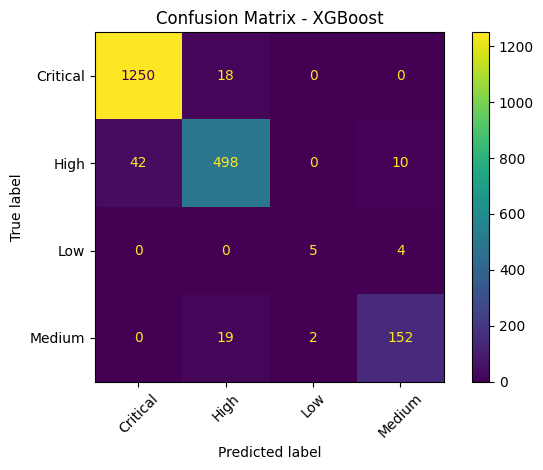

In [17]:
best_model_name = results_df.loc[results_df["F1 Score"].idxmax(), "Model"]
print("Best Model:", best_model_name)

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

best_model = models[best_model_name]
y_pred_best = best_model.predict(X_test)

# If the best model is XGBoost, its predictions are integer-encoded.
# We need to decode them back to string labels to match y_test.
if best_model_name == "XGBoost":
    y_pred_best = le.inverse_transform(y_pred_best)

plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    xticks_rotation=45
)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

In [18]:
import joblib
import os

best_model = models[best_model_name]
preprocessor_fitted = best_model.named_steps["preprocessor"]
classifier = best_model.named_steps["classifier"]

feature_names = preprocessor_fitted.get_feature_names_out()

if hasattr(classifier, "feature_importances_"):
    importance = classifier.feature_importances_
elif hasattr(classifier, "coef_"):
    importance = np.mean(np.abs(classifier.coef_), axis=0)

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

print("Top 15 Important Features:")
print(feature_importance_df.head(15))

# Save the model
joblib.dump(best_model, "cyber_risk_best_model_10k.pkl")
print("\nBest model saved successfully. File exists:", os.path.exists("cyber_risk_best_model_10k.pkl"))

Top 15 Important Features:
                           Feature  Importance
13             cat__mfa_enabled_No    0.071650
37         cat__asset_inventory_No    0.036947
81   num__critical_vulnerabilities    0.035367
43   cat__backup_frequency_Unknown    0.033894
30       cat__device_encryption_No    0.032197
49  cat__incident_response_plan_No    0.030559
55       cat__phishing_training_No    0.030310
18        cat__firewall_enabled_No    0.026827
39          cat__backup_enabled_No    0.026477
45           cat__backup_tested_No    0.026256
59         cat__data_encryption_No    0.025578
70     cat__security_monitoring_No    0.023980
20    cat__network_segmentation_No    0.023861
35  cat__vulnerability_scanning_No    0.023246
28             cat__edr_enabled_No    0.023171

Best model saved successfully. File exists: True


In [19]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "XGBoost": xgb_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_true_eval = y_test_encoded if name == "XGBoost" else y_test

    acc = accuracy_score(y_true_eval, y_pred) * 100
    prec = precision_score(y_true_eval, y_pred, average="weighted", zero_division=0) * 100
    rec = recall_score(y_true_eval, y_pred, average="weighted", zero_division=0) * 100
    f1 = f1_score(y_true_eval, y_pred, average="weighted", zero_division=0) * 100

    results.append({
        "Model": name,
        "Accuracy (%)": f"{acc:.2f}%",
        "Precision (%)": f"{prec:.2f}%",
        "Recall (%)": f"{rec:.2f}%",
        "F1 Score (%)": f"{f1:.2f}%"
    })

# Convert results into DataFrame and Display
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

              Model Accuracy (%) Precision (%) Recall (%) F1 Score (%)
Logistic Regression       93.35%        93.72%     93.35%       93.47%
      Decision Tree       91.90%        92.11%     91.90%       91.98%
      Random Forest       95.20%        95.15%     95.20%       95.15%
            XGBoost       95.25%        95.18%     95.25%       95.20%
